# CS5785 Midterm — Part 1: Semi-supervised labeling of clinical-trial stopping reasons

**Task.** 1,171 training trials, only 157 with reason labels (Safety, Funding, Efficacy, Recruitment, Other; multi-label). Use unsupervised / semi-supervised learning to fill in the 1,014 missing labels, select the model on `part1_val.csv` (78 trials), and predict the 312 test trials (latest start years).

**Notebook map**
0. Setup & data
1. Method library (all models used below)
2. EDA: label rates, label co-occurrence, the start-year shift, a t-SNE of the reason embeddings
3. Evaluation protocol
4. Exp A: preprocessing (standardize vs L2-normalize vs PCA)
5. Exp B: unsupervised diagnostics (K-Means k-sweep, GMM BIC / covariance types / EM convergence, HDBSCAN & DBSCAN)
6. Exp C: main comparison of all labeling methods
7. Exp D: learning curve (when does unlabeled data help?)
8. Exp E: feature ablation (why adding everything doesn't help)
9. Exp F: decision thresholds
10. Exp G: label-prior shift between early and late trials (EM prior correction)
11. Final model → Kaggle submission + **reason-label handoff file for Part 2**
12. Results summary

Everything runs top to bottom in Colab (CPU) in about 10–15 minutes. No deep learning is used.

## 0. Setup & data

In [1]:
import sys, os, subprocess, zipfile, glob
IN_COLAB = 'google.colab' in sys.modules
try:
    import rdkit
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'rdkit'], check=True)

# Data location. In Colab, either (a) upload the Kaggle zip when prompted, or (b) set DATA_DIR to a Drive folder.
DATA_DIR = os.environ.get('P1_DATA_DIR', './data/')
if not os.path.exists(os.path.join(DATA_DIR, 'part1_train.csv')):
    zips = glob.glob('*.zip')
    if not zips and IN_COLAB:
        from google.colab import files
        print('Upload cs-5785-midterm-2026-clinical-trial-reason-prediction.zip'); files.upload(); zips = glob.glob('*.zip')
    os.makedirs(DATA_DIR, exist_ok=True)
    for z in zips: zipfile.ZipFile(z).extractall(DATA_DIR)
os.makedirs('figures', exist_ok=True); os.makedirs('outputs', exist_ok=True)
print(sorted(os.listdir(DATA_DIR)))

['part1_sample_submission.csv', 'part1_test.csv', 'part1_train.csv', 'part1_val.csv', 'pathway_catalog.csv']


In [2]:
import matplotlib.pyplot as plt, matplotlib as mpl
# Fixed categorical order (validated colorblind-safe palette); grays for context.
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
INK, INK2, GRID, GRAY = '#0b0b0b', '#52514e', '#e4e3df', '#b8b7b0'
mpl.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GRAY, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'axes.titlecolor': INK,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': .6, 'axes.axisbelow': True, 'font.size': 9.5, 'legend.frameon': False,
    'lines.linewidth': 2})
SEED = 0

## 1. Method library
Defined first so every experiment below shares the same code. Each label model has `fit(X_labeled, Y_labeled, X_unlabeled)` and `predict_proba(X)`, which returns an (n × 5) matrix of per-reason probabilities.

In [3]:
import numpy as np, pandas as pd, ast, warnings
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, HDBSCAN, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.semi_supervised import LabelSpreading
from sklearn.metrics import f1_score
warnings.filterwarnings('ignore')

L = ['Safety', 'Funding', 'Efficacy', 'Recruitment', 'Other']
D = DATA_DIR

def load():
    tr = pd.read_csv(D + 'part1_train.csv'); va = pd.read_csv(D + 'part1_val.csv'); te = pd.read_csv(D + 'part1_test.csv')
    return tr, va, te

EMB = [f'emb_{i}' for i in range(150)]

# ---------- preprocessing ----------
def prep_emb(fit_X, Xs, mode='std', pca=None, seed=0):
    """mode: 'std' standardize | 'l2' standardize then L2-normalize | 'raw'. pca: n comps or None."""
    sc = StandardScaler().fit(fit_X)
    f = lambda X: sc.transform(X) if mode != 'raw' else X.copy()
    out = [f(X) for X in Xs]; fz = f(fit_X)
    if pca:
        p = PCA(pca, random_state=seed).fit(fz); out = [p.transform(X) for X in out]
        s2 = StandardScaler().fit(p.transform(fz)) if False else None
    if mode == 'l2':
        out = [normalize(X) for X in out]
    return out

# ---------- decision rule ----------
def decide(P, t=0.5, min_one=True):
    Y = (P >= t).astype(int)
    if min_one:
        e = Y.sum(1) == 0
        Y[e, P[e].argmax(1)] = 1
    return Y

def decide_pl(P, ts):
    Y = (P >= np.asarray(ts)[None]).astype(int)
    e = Y.sum(1) == 0; Y[e, (P[e] / np.asarray(ts)[None]).argmax(1)] = 1
    return Y

def metrics(Y, Yhat):
    per = f1_score(Y, Yhat, average=None, zero_division=0)
    return dict(sample_f1=f1_score(Y, Yhat, average='samples', zero_division=0),
                macro_f1=per.mean(), **{f'F1_{l}': v for l, v in zip(L, per)})

# ---------- label models: fit(Xl, Yl, Xu) -> predict_proba(X) ----------
class LR:
    name = 'LogReg OvR'
    def __init__(s, C=1.0, cw='balanced'): s.C, s.cw = C, cw
    def fit(s, Xl, Yl, Xu=None, w=None):
        s.m = []
        for j in range(Yl.shape[1]):
            y = Yl[:, j]
            if y.min() == y.max(): s.m.append(float(y[0])); continue
            m = LogisticRegression(C=s.C, class_weight=s.cw, max_iter=3000)
            m.fit(Xl, y, sample_weight=None if w is None else w[:, j] if w.ndim == 2 else w)
            s.m.append(m)
        return s
    def predict_proba(s, X):
        return np.column_stack([np.full(len(X), m) if isinstance(m, float) else m.predict_proba(X)[:, 1] for m in s.m])

class KNN:
    name = 'kNN (cosine)'
    def __init__(s, k=10, prior=1.0): s.k, s.prior = k, prior
    def fit(s, Xl, Yl, Xu=None):
        s.nn = NearestNeighbors(n_neighbors=min(s.k, len(Xl)), metric='cosine').fit(Xl); s.Y = Yl; s.p = Yl.mean(0); return s
    def predict_proba(s, X):
        d, i = s.nn.kneighbors(X); w = 1 / (d + 1e-3)
        num = (w[..., None] * s.Y[i]).sum(1) + s.prior * s.p
        return num / (w.sum(1, keepdims=True) + s.prior)

def _cluster_rates(R, Yl, alpha, prior):
    # R: (n_l, K) soft/hard responsibilities of labeled points; smoothed per-cluster label rate
    return (R.T @ Yl + alpha * prior[None]) / (R.sum(0)[:, None] + alpha)

class KMeansLabel:
    name = 'K-Means cluster-then-label'
    def __init__(s, k=20, alpha=1.0, seed=0, n_init=10): s.k, s.alpha, s.seed, s.n_init = k, alpha, seed, n_init
    def fit(s, Xl, Yl, Xu):
        X = np.vstack([Xl, Xu]); s.km = KMeans(s.k, n_init=s.n_init, random_state=s.seed).fit(X)
        R = np.eye(s.k)[s.km.predict(Xl)]; s.M = _cluster_rates(R, Yl, s.alpha, Yl.mean(0)); return s
    def predict_proba(s, X): return s.M[s.km.predict(X)]

class GMMLabel:
    name = 'GMM soft cluster-then-label'
    def __init__(s, k=20, cov='diag', alpha=1.0, seed=0, reg=1e-3): s.k, s.cov, s.alpha, s.seed, s.reg = k, cov, alpha, seed, reg
    def fit(s, Xl, Yl, Xu):
        X = np.vstack([Xl, Xu])
        s.g = GaussianMixture(s.k, covariance_type=s.cov, random_state=s.seed, reg_covar=s.reg, n_init=3,
                              max_iter=500, tol=1e-4, init_params='k-means++').fit(X)
        s.M = _cluster_rates(s.g.predict_proba(Xl), Yl, s.alpha, Yl.mean(0)); return s
    def predict_proba(s, X): return s.g.predict_proba(X) @ s.M

class DensityLabel:
    """HDBSCAN/DBSCAN clusters; noise points (and clusters w/o labeled members) fall back to kNN."""
    name = 'HDBSCAN cluster-then-label (+kNN fallback)'
    def __init__(s, algo='hdbscan', min_cluster_size=10, eps=0.5, alpha=1.0, k=10):
        s.algo, s.mcs, s.eps, s.alpha, s.k = algo, min_cluster_size, eps, alpha, k
    def fit(s, Xl, Yl, Xu):
        X = np.vstack([Xl, Xu])
        cl = (HDBSCAN(min_cluster_size=s.mcs, metric='euclidean', copy=True) if s.algo == 'hdbscan'
              else DBSCAN(eps=s.eps, min_samples=5, metric='cosine')).fit(X)
        s.lab_all = cl.labels_; s.Xall = X; s.noise_frac = (cl.labels_ == -1).mean(); s.n_clusters = cl.labels_.max() + 1
        lab_l = cl.labels_[:len(Xl)]; K = max(s.n_clusters, 1)
        R = np.zeros((len(Xl), K)); ok = lab_l >= 0; R[np.where(ok)[0], lab_l[ok]] = 1
        s.M = _cluster_rates(R, Yl, s.alpha, Yl.mean(0)); s.has = R.sum(0) > 0
        s.nn_all = NearestNeighbors(n_neighbors=1).fit(X)
        s.fb = KNN(s.k).fit(Xl, Yl); return s
    def predict_proba(s, X):
        # assign new points to cluster of nearest clustered training point (approximate predict)
        _, i = s.nn_all.kneighbors(X); c = s.lab_all[i[:, 0]]
        P = s.fb.predict_proba(X); use = (c >= 0) & s.has[np.clip(c, 0, None)]
        P[use] = 0.5 * s.M[c[use]] + 0.5 * P[use]   # blend cluster rate with local kNN
        return P

class Spread:
    name = 'Label Spreading (kNN graph)'
    def __init__(s, k=10, alpha=0.2, kernel='knn', gamma=20): s.k, s.alpha, s.kernel, s.gamma = k, alpha, kernel, gamma
    def fit(s, Xl, Yl, Xu):
        s.X = np.vstack([Xl, Xu]); s.ms = []
        for j in range(Yl.shape[1]):
            y = np.r_[Yl[:, j], -np.ones(len(Xu), int)].astype(int)
            m = LabelSpreading(kernel=s.kernel, n_neighbors=s.k, gamma=s.gamma, alpha=s.alpha, max_iter=200).fit(s.X, y)
            s.ms.append(m)
        s.p = Yl.mean(0); return s
    def predict_proba(s, X):
        P = np.column_stack([m.predict_proba(X)[:, list(m.classes_).index(1)] if 1 in m.classes_ else np.zeros(len(X)) for m in s.ms])
        bad = ~np.isfinite(P); P[bad] = np.broadcast_to(s.p, P.shape)[bad]   # isolated nodes -> prior
        return P

class SelfTrain:
    name = 'Self-training LogReg'
    def __init__(s, C=1.0, thr=0.9, iters=5): s.C, s.thr, s.iters = C, thr, iters
    def fit(s, Xl, Yl, Xu):
        m = LR(s.C).fit(Xl, Yl)
        for _ in range(s.iters):
            Pu = m.predict_proba(Xu)
            conf = np.where(Pu > 0.5, Pu, 1 - Pu).min(1) >= s.thr   # confident on all 5 labels
            if conf.sum() == 0: break
            m = LR(s.C).fit(np.vstack([Xl, Xu[conf]]), np.vstack([Yl, decide(Pu[conf])]))
        s.m = m; s.n_pseudo = int(conf.sum()); return s
    def predict_proba(s, X): return s.m.predict_proba(X)

class Augmented:
    """Pseudo-label unlabeled data with a teacher (any method above), then train a LogReg student
    on labeled + pseudo-labeled data (soft-label weighting by teacher confidence)."""
    def __init__(s, teacher, C=1.0, w_pseudo=0.5, hard=True):
        s.teacher, s.C, s.wp, s.hard = teacher, C, w_pseudo, hard
        s.name = f'Augmented LR <- {teacher.name}'
    def fit(s, Xl, Yl, Xu):
        s.teacher.fit(Xl, Yl, Xu); Pu = s.teacher.predict_proba(Xu); s.Pu = Pu
        Yu = decide(Pu) if s.hard else (Pu > 0.5).astype(int)
        conf = np.abs(Pu - 0.5) * 2               # per-label confidence in [0,1]
        X = np.vstack([Xl, Xu]); Y = np.vstack([Yl, Yu])
        W = np.vstack([np.ones_like(Yl, float), s.wp * conf])
        s.m = LR(s.C).fit(X, Y, w=W); return s
    def predict_proba(s, X): return s.m.predict_proba(X)

class GMMFeatLR:
    name = 'LogReg on [emb + GMM posteriors]'
    def __init__(s, k=20, C=1.0, cov='diag', scale=3.0): s.k, s.C, s.cov, s.scale = k, C, cov, scale
    def fit(s, Xl, Yl, Xu):
        s.g = GaussianMixture(s.k, covariance_type=s.cov, random_state=0, reg_covar=1e-3, n_init=3).fit(np.vstack([Xl, Xu]))
        s.m = LR(s.C).fit(s._f(Xl), Yl); return s
    def _f(s, X): return np.hstack([X, s.scale * s.g.predict_proba(X)])
    def predict_proba(s, X): return s.m.predict_proba(s._f(X))

class Ensemble:
    def __init__(s, models, w=None): s.models, s.w = models, w; s.name = 'Ensemble(' + ' + '.join(m.name.split(' ')[0] for m in models) + ')'
    def fit(s, Xl, Yl, Xu):
        for m in s.models: m.fit(Xl, Yl, Xu)
        return s
    def predict_proba(s, X):
        w = s.w or [1] * len(s.models)
        return sum(wi * m.predict_proba(X) for wi, m in zip(w, s.models)) / sum(w)

# ---------- prior shift (Saerens, Latinne & Decaestecker 2002), per label ----------
def em_prior_shift(P, train_prior, iters=100, tol=1e-6):
    P = np.clip(P, 1e-6, 1 - 1e-6); pi = train_prior.copy(); new = P
    for _ in range(iters):
        a = pi / train_prior; b = (1 - pi) / (1 - train_prior)
        new = a * P / (a * P + b * (1 - P))
        npi = new.mean(0)
        if np.abs(npi - pi).max() < tol: pi = npi; break
        pi = npi
    return new, pi

# ---------- extra (non-embedding) features ----------
def parse_list(s):
    if pd.isna(s): return []
    try:
        v = ast.literal_eval(s)
        out = []
        for x in (v if isinstance(v, list) else [v]):
            if isinstance(x, str) and x.startswith('['):
                try: out += ast.literal_eval(x); continue
                except Exception: pass
            out.append(x)
        return [str(x) for x in out]
    except Exception:
        return [t.strip() for t in str(s).split(';') if t.strip()]

def semi(s): return [] if pd.isna(s) else [t.strip() for t in str(s).split(';') if t.strip()]

class Consensus:
    """Teacher = several label models; a pseudo-label is kept only where all teachers agree
    (after the >=1-label rule). Student = LogReg on labeled + agreed pseudo-labels."""
    def __init__(s, teachers, C=1.0, w_pseudo=1.0, cw='balanced'):
        s.teachers, s.C, s.wp, s.cw = teachers, C, w_pseudo, cw; s.name = 'Consensus-augmented LR'
    def fit(s, Xl, Yl, Xu):
        Ys = [decide(t.fit(Xl, Yl, Xu).predict_proba(Xu)) for t in s.teachers]
        agree = np.all([np.all(Y == Ys[0], 1) for Y in Ys[1:]], 0)
        s.agree_frac = agree.mean(); s.Yu = Ys[0]; s.agree = agree
        X = np.vstack([Xl, Xu[agree]]); Y = np.vstack([Yl, Ys[0][agree]])
        w = np.r_[np.ones(len(Xl)), s.wp * np.ones(agree.sum())]
        s.m = LR(s.C, s.cw).fit(X, Y, w=w); return s
    def predict_proba(s, X): return s.m.predict_proba(X)

# ---------- non-embedding feature blocks ----------
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer
def build_blocks(tr, va, te, catalog, seed=0):
    from rdkit import Chem, RDLogger; from rdkit.Chem import rdFingerprintGenerator
    RDLogger.DisableLog('rdApp.*')
    allx = pd.concat([tr, va, te], ignore_index=True); ntr = len(tr)
    B = {}
    yr = allx.start_year.values.astype(float)[:, None]; B['start_year'] = (yr - yr[:ntr].mean()) / yr[:ntr].std()
    def tfidf_svd(col, k, **kw):
        txt = allx[col].fillna('').astype(str)
        tv = TfidfVectorizer(**kw).fit(txt[:ntr]); M = tv.transform(txt)
        sv = TruncatedSVD(k, random_state=seed).fit(M[:ntr]); Z = sv.transform(M)
        return StandardScaler().fit(Z[:ntr]).transform(Z)
    B['disease_tfidf'] = tfidf_svd('diseases_cleaned', 30, min_df=2, ngram_range=(1, 2))
    B['criteria_tfidf'] = tfidf_svd('criteria', 50, min_df=3, max_features=20000, ngram_range=(1, 2), stop_words='english', sublinear_tf=True)
    icd = [sorted({c[0] for c in parse_list(s) if c}) for s in allx.icdcodes]
    B['icd_chapter'] = MultiLabelBinarizer().fit(icd[:ntr]).transform(icd).astype(float)
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
    def fp(s):
        if pd.isna(s): return np.zeros(1024)
        f = [gen.GetFingerprintAsNumPy(m) for x in str(s).split(';') if (m := Chem.MolFromSmiles(x.strip())) is not None]
        return np.max(f, 0) if f else np.zeros(1024)
    FP = np.vstack([fp(s) for s in allx.drug_smiles]).astype(float)
    sv = TruncatedSVD(30, random_state=seed).fit(FP[:ntr]); Z = sv.transform(FP)
    B['morgan_fp_svd'] = StandardScaler().fit(Z[:ntr]).transform(Z)
    lvl0 = set(catalog.loc[catalog.pathway_level <= 1, 'reactome_id'])
    pw = [sorted(set(semi(s)) & lvl0) for s in allx.drug_pathways]
    B['pathways_lvl0-1'] = MultiLabelBinarizer().fit(pw[:ntr]).transform(pw).astype(float)
    act = [sorted(set(a.lower() for a in semi(s))) for s in allx.drug_actions]
    mlb = MultiLabelBinarizer().fit(act[:ntr]); A = mlb.transform(act).astype(float)
    B['drug_actions'] = A[:, A[:ntr].sum(0) >= 5]
    B['has_matched_drug'] = allx.matched_drugs.notna().values.astype(float)[:, None]
    n1, n2 = ntr, ntr + len(va)
    return {k: (v[:n1], v[n1:n2], v[n2:]) for k, v in B.items()}

class BalancedConsensus(Consensus):
    """Consensus, but pseudo-label weights are re-scaled so each label's positive pseudo-label mass matches
    the labeled-set prior (fixes the 'teachers only agree on Recruitment' bias)."""
    def fit(s, Xl, Yl, Xu):
        Ys = [decide(t.fit(Xl, Yl, Xu).predict_proba(Xu)) for t in s.teachers]
        agree = np.all([np.all(Y == Ys[0], 1) for Y in Ys[1:]], 0); s.agree_frac = agree.mean()
        Yu = Ys[0][agree]; s.Yu, s.agree = Ys[0], agree
        prior = Yl.mean(0); rate = np.clip(Yu.mean(0), 1e-3, None)
        Wpos = np.clip(prior / rate, 0.2, 5.0)                      # per-label weight on positive pseudo-labels
        W = np.where(Yu == 1, Wpos[None], 1.0) * s.wp
        X = np.vstack([Xl, Xu[agree]]); Y = np.vstack([Yl, Yu]); W = np.vstack([np.ones_like(Yl, float), W])
        s.m = LR(s.C, s.cw).fit(X, Y, w=W); return s

In [4]:
from sklearn.model_selection import KFold
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
import time, pickle
tr, va, te = load(); catalog = pd.read_csv(D + 'pathway_catalog.csv')
islab = (tr.Safety != -100).values
lab, unl = tr[islab], tr[~islab]
Yl, Yv = lab[L].values, va[L].values
def space(mode, pca=None):
    # every transform is fit on part1_train embeddings only (labeled + unlabeled); val/test are only transformed
    return prep_emb(tr[EMB].values, [lab[EMB].values, unl[EMB].values, va[EMB].values, te[EMB].values], mode, pca)
SP = {'std': space('std'), 'l2': space('l2')}
print('labeled', len(lab), '| unlabeled', len(unl), '| val', len(va), '| test', len(te))

labeled 157 | unlabeled 1014 | val 78 | test 312


## 2. EDA

In [5]:
rates = pd.DataFrame({'train labeled (157)': lab[L].mean(), 'val (78)': va[L].mean()}).T.round(3)
display(rates)
print('labels per trial (labeled):', lab[L].sum(axis=1).value_counts().to_dict(), '| (val):', va[L].sum(axis=1).value_counts().to_dict())
co = pd.DataFrame(Yl.T @ Yl, index=L, columns=L); print('label co-occurrence (train labeled):'); display(co)
yrs = pd.DataFrame({n: d.start_year.describe()[['min', '50%', 'max']] for n, d in
                    [('labeled', lab), ('unlabeled', unl), ('val', va), ('test', te)]}).T
display(yrs)
print('matched-drug coverage:', tr.matched_drugs.notna().mean().round(3))

,Safety,Funding,Efficacy,Recruitment,Other
train labeled (157),0.102,0.051,0.108,0.643,0.159
val (78),0.115,0.051,0.179,0.641,0.128


labels per trial (labeled): {1: 147, 2: 10} | (val): {1: 69, 2: 9}
label co-occurrence (train labeled):


,Safety,Funding,Efficacy,Recruitment,Other
Safety,16,0,0,0,0
Funding,0,8,0,4,0
Efficacy,0,0,17,0,0
Recruitment,0,4,0,101,6
Other,0,0,0,6,25


,min,50%,max
labeled,1993.0,2001.0,2010.0
unlabeled,2003.0,2007.0,2010.0
val,1999.0,2006.0,2009.0
test,2010.0,2011.0,2016.0


matched-drug coverage: 0.561


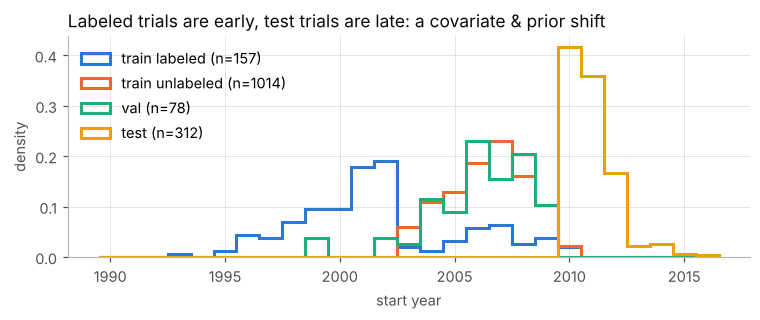

In [6]:
fig, ax = plt.subplots(figsize=(7, 3))
bins = np.arange(1990, 2018) - .5
for (n, d), c in zip([('train labeled', lab), ('train unlabeled', unl), ('val', va), ('test', te)], [BLUE, ORANGE, AQUA, YELLOW]):
    ax.hist(d.start_year, bins=bins, histtype='step', lw=2, color=c, label=f'{n} (n={len(d)})', density=True)
ax.set_xlabel('start year'); ax.set_ylabel('density'); ax.legend(loc='upper left')
ax.set_title('Labeled trials are early, test trials are late: a covariate & prior shift', loc='left')
plt.tight_layout(); plt.savefig('figures/fig1_start_year_shift.png'); plt.show()

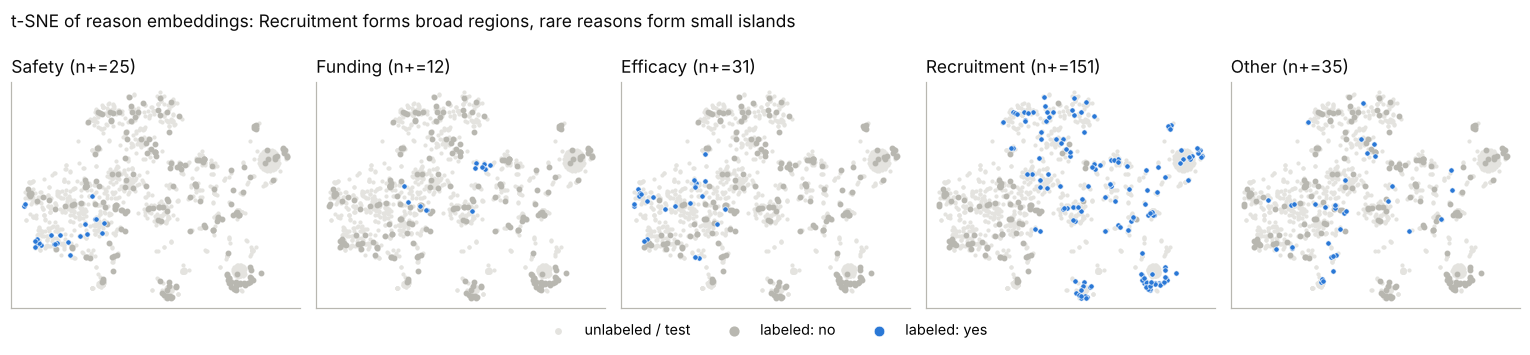

In [7]:
# t-SNE of all 1,561 reason embeddings (standardized, L2-normalised); one panel per reason (small multiples)
Xall = np.vstack(SP['l2']); n_l, n_u, n_v = len(lab), len(unl), len(va)
Z = TSNE(2, perplexity=30, init='pca', random_state=SEED, metric='cosine').fit_transform(Xall)
Yknown = np.vstack([Yl, np.full((n_u, 5), -1), Yv, np.full((len(te), 5), -1)])
fig, axs = plt.subplots(1, 5, figsize=(14, 3.1), sharex=True, sharey=True)
for j, (ax, l) in enumerate(zip(axs, L)):
    ax.scatter(*Z[Yknown[:, j] == -1].T, s=3, c=GRID, label='unlabeled / test')
    ax.scatter(*Z[Yknown[:, j] == 0].T, s=8, c=GRAY, label='labeled: no')
    ax.scatter(*Z[Yknown[:, j] == 1].T, s=12, c=BLUE, edgecolor='white', linewidth=.4, label='labeled: yes')
    ax.set_title(f'{l} (n+={int((Yknown[:, j] == 1).sum())})', loc='left'); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
h, l_ = axs[0].get_legend_handles_labels(); fig.legend(h, l_, loc='lower center', ncol=3, markerscale=2, bbox_to_anchor=(.5, -.02))
fig.suptitle('t-SNE of reason embeddings: Recruitment forms broad regions, rare reasons form small islands', x=.01, ha='left', color=INK)
plt.tight_layout(rect=(0, .06, 1, 1)); plt.savefig('figures/fig2_tsne_by_reason.png', bbox_inches='tight'); plt.show()

**What the EDA tells us**
- ~93% of labeled trials have exactly one reason, so a "≥ 1 label, rarely 2" decision rule fits the data. Every trial stopped for *some* reason, and predicting an empty label set scores sample-F1 = 0, so we always assign at least one label (the arg-max).
- The classes are very imbalanced: Recruitment ≈ 64%, Funding ≈ 5% (only 8 labeled examples). Macro-F1 depends heavily on Funding and Other.
- The labeled trials are mostly the *earliest* ones (median 2001), the unlabeled ones median 2007, val median 2006, and test 2010–2016. The spec warns Safety becomes more common over time, so we handle the label-prior shift explicitly in Exp G.
- In the t-SNE, the reasons occupy fairly separable regions of the embedding space. That's why the embeddings, not the drug or criteria features, carry the signal (see Exp E).

## 3. Evaluation protocol
- **Metric:** sample-wise F1 (the Kaggle metric), plus per-reason F1 and macro-F1.
- **Validation is tiny (78 trials, 4 with Funding).** One trial moves sample-F1 by ~1 point. So for *model selection* we use **5×5 repeated K-fold CV on the 235 fully labeled trials (157 train-labeled + 78 val)**. In every fold the 1,014 unlabeled trials are available to the semi-supervised methods, and the held-out fold is never seen. We also report the **val score of a model trained on the 157 labeled trials only**, as the spec asks, with bootstrap CIs for the final model.
- **No leakage:** scalers / PCA / TF-IDF / SVD are fit on `part1_train` only. Test features are not used to fit anything except in the optional transductive experiment, which is reported separately and *not* used for the submission.
- **Decision rule:** `decide(P, t)`. Predict every reason with p ≥ t; if none qualifies, predict the arg-max reason.

In [8]:
def cv_oof(mk, Xl, Xu, Xv, reps=5, k=5):
    Xp, Yp = np.vstack([Xl, Xv]), np.vstack([Yl, Yv]); out = []
    for r in range(reps):
        P = np.zeros_like(Yp, float)
        for a, b in KFold(k, shuffle=True, random_state=100 + r).split(Xp):
            P[b] = mk().fit(Xp[a], Yp[a], Xu).predict_proba(Xp[b])
        out.append(P)
    return out, Yp
def evaluate(name, mk, sp='std', reps=5, t=0.5, extra=None):
    Xl, Xu, Xv, Xt = SP[sp] if isinstance(sp, str) else sp
    t0 = time.time(); oof, Yp = cv_oof(mk, Xl, Xu, Xv, reps)
    cvm = [metrics(Yp, decide(P, t)) for P in oof]
    m = mk().fit(Xl, Yl, Xu); v = metrics(Yv, decide(m.predict_proba(Xv), t))
    row = dict(method=name, space=sp if isinstance(sp, str) else 'custom', cv_sample_f1=np.mean([c['sample_f1'] for c in cvm]),
               cv_sd=np.std([c['sample_f1'] for c in cvm]), cv_macro_f1=np.mean([c['macro_f1'] for c in cvm]),
               val_sample_f1=v['sample_f1'], val_macro_f1=v['macro_f1'], **{f'val_F1_{l}': v[f'F1_{l}'] for l in L}, sec=time.time() - t0)
    if extra: row.update(extra(m))
    return row, m, oof
fmt = lambda df: df.style.format({c: '{:.3f}' for c in df.columns if df[c].dtype.kind == 'f'})

## 4. Exp A: preprocessing (2+ options)
The embeddings are tiny-valued and randomly rotated. We compare **standardize** (z-score per dimension), **standardize + L2-normalize** (cosine geometry, the natural one for sentence embeddings), and **PCA to 20 / 50 dims** on top of standardization. Each is crossed with a supervised, a centroid-clustering, a distribution-clustering and a graph-based method.

In [9]:
spaces = {'std': SP['std'], 'l2': SP['l2'], 'std+PCA50': space('std', 50), 'std+PCA20': space('std', 20), 'l2+PCA20': space('l2', 20)}
probe = {'LogReg OvR': lambda: LR(1.0), 'K-Means (k=50)': lambda: KMeansLabel(50, n_init=4),
         'GMM diag (k=25)': lambda: GMMLabel(25, 'diag'), 'Label Spreading': lambda: Spread(10)}
rows = []
for sn, spc in spaces.items():
    for mn, mk in probe.items():
        r, _, _ = evaluate(mn, mk, spc, reps=3); r['space'] = sn; rows.append(r)
A = pd.DataFrame(rows)
pivot = A.pivot(index='method', columns='space', values='cv_sample_f1')[list(spaces)]
display(fmt(pivot)); A.to_csv('outputs/expA_preprocessing.csv', index=False)

space,std,l2,std+PCA50,std+PCA20,l2+PCA20
method,,,,,
GMM diag (k=25),0.786,0.785,0.768,0.792,0.806
K-Means (k=50),0.814,0.843,0.813,0.828,0.843
Label Spreading,0.837,0.849,0.847,0.872,0.864
LogReg OvR,0.894,0.866,0.887,0.854,0.857


**Takeaways (Exp A)**
- **PCA has opposite effects on the two families.** It *hurts* logistic regression (0.894 → 0.854 sample-F1 at 20 dims). The directions that separate *rare* reasons (Funding, Other) carry little variance, so PCA throws them away: unsupervised variance ≠ label-relevant variance. It *helps* the distance-based methods (Label Spreading 0.837 → 0.872, GMM 0.786 → 0.806, K-Means 0.814 → 0.843), because dropping 130 low-variance, noisy dimensions makes nearest-neighbour distances more meaningful (curse of dimensionality / hubness).
- **L2-normalization helps the distance-based methods** (K-Means 0.814 → 0.843, Label Spreading 0.837 → 0.849), because sentence-embedding similarity is angular. It hurts logistic regression at fixed C = 1 (0.894 → 0.866): unit-norm features are tiny, so the same C means much stronger regularisation.
- No space wins for every model, so each model gets its own: full-dimensional **standardized** features for the linear models (our best performers), **standardized + L2** for the graph / cluster methods.

## 5. Exp B: unsupervised diagnostics
### 5a. K-Means: number of clusters
K-Means++ initialisation, 4–10 restarts (`n_init`), Lloyd iterations until the centroid shift < 1e-4 (sklearn default `tol`), max 300 iterations. Cluster-then-label: each cluster's label probability is the Laplace-smoothed mean label of its labeled members, `(Σ y + α·prior)/(n + α)` with α = 1.

,k,inertia,silhouette,labeled_purity,clusters_with_labels,n_iter,cv_sample_f1,val_sample_f1
0,5,806.525,0.214,0.650,1.000,19,0.652,0.714
1,10,679.377,0.249,0.720,1.000,20,0.709,0.761
2,20,575.205,0.282,0.771,0.950,19,0.781,0.812
3,30,526.993,0.297,0.834,0.933,17,0.818,0.846
4,50,466.083,0.319,0.892,0.860,9,0.843,0.799
5,75,411.029,0.322,0.917,0.720,9,0.806,0.778
6,100,372.987,0.345,0.917,0.620,6,0.803,0.795
7,150,312.097,0.368,0.949,0.487,5,0.793,0.761


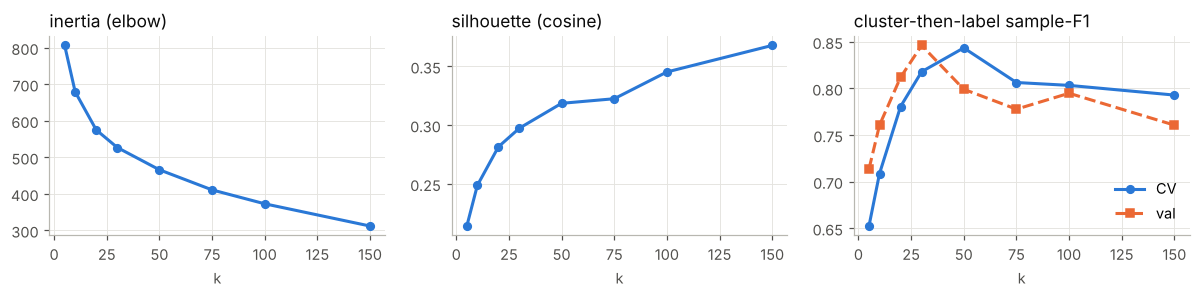

In [10]:
Xl2, Xu2, Xv2, Xt2 = SP['l2']; Xtr2 = np.vstack([Xl2, Xu2]); rows = []
for k in [5, 10, 20, 30, 50, 75, 100, 150]:
    km = KMeans(k, n_init=4, random_state=SEED).fit(Xtr2)
    lab_c = km.predict(Xl2)
    # purity: share of labeled points whose cluster's majority reason-set equals their own
    keys = pd.Series([''.join(map(str, y)) for y in Yl]); maj = keys.groupby(lab_c).agg(lambda s: s.value_counts().index[0])
    purity = (keys.values == maj.loc[lab_c].values).mean()
    covered = len(np.unique(lab_c)) / k
    r, _, _ = evaluate(f'K-Means k={k}', lambda k=k: KMeansLabel(k, n_init=4), 'l2', reps=3)
    rows.append(dict(k=k, inertia=km.inertia_, silhouette=silhouette_score(Xtr2, km.labels_, metric='cosine'),
                     labeled_purity=purity, clusters_with_labels=covered, n_iter=km.n_iter_, cv_sample_f1=r['cv_sample_f1'], val_sample_f1=r['val_sample_f1']))
B1 = pd.DataFrame(rows); display(fmt(B1)); B1.to_csv('outputs/expB_kmeans_sweep.csv', index=False)
fig, axs = plt.subplots(1, 3, figsize=(11, 2.8))
axs[0].plot(B1.k, B1.inertia, 'o-', color=BLUE, ms=5); axs[0].set_title('inertia (elbow)', loc='left')
axs[1].plot(B1.k, B1.silhouette, 'o-', color=BLUE, ms=5); axs[1].set_title('silhouette (cosine)', loc='left')
axs[2].plot(B1.k, B1.cv_sample_f1, 'o-', color=BLUE, ms=5, label='CV'); axs[2].plot(B1.k, B1.val_sample_f1, 's--', color=ORANGE, ms=5, label='val')
axs[2].set_title('cluster-then-label sample-F1', loc='left'); axs[2].legend()
for a in axs: a.set_xlabel('k')
plt.tight_layout(); plt.savefig('figures/fig3_kmeans_k_sweep.png'); plt.show()

**Takeaways (5a)**
- There is no clean elbow, and the silhouette is low (0.21–0.37) and keeps rising with k, so there is no "natural" number of clusters. The embedding space is a continuum, not well-separated blobs.
- **Purity vs coverage trade-off:** as k grows, labeled-member purity rises (0.65 → 0.95), but the share of clusters that contain *any* labeled trial falls (100% → 49%). Unlabeled-only clusters fall back to the global prior. Cluster-then-label CV F1 therefore peaks at **k ≈ 50 (0.843)** and declines after. With 157 labels, the *labels-per-cluster* budget, not cluster quality, is the binding constraint.
- Even the best K-Means labeling (0.84) is well below a linear classifier (0.895). Hard clusters smear rare reasons into Recruitment-dominated neighbourhoods.

### 5b. GMM: components, covariance type, EM convergence
EM with k-means++ initialisation, 3 restarts, convergence tolerance 1e-4 on the per-sample log-likelihood lower bound, max 500 iterations, `reg_covar` = 1e-3 (needed: in 150-d with ~1,200 points, full covariances are singular). Model selection by BIC.

,cov,dims,k,bic,converged,n_iter
9,diag,150d,15,-495076.962994,True,39
16,diag,PCA20,25,-30435.660293,True,43
25,full,PCA20,5,-25316.127204,True,30
5,spherical,150d,40,-515475.299095,True,66
23,tied,PCA20,40,-20996.029358,True,71


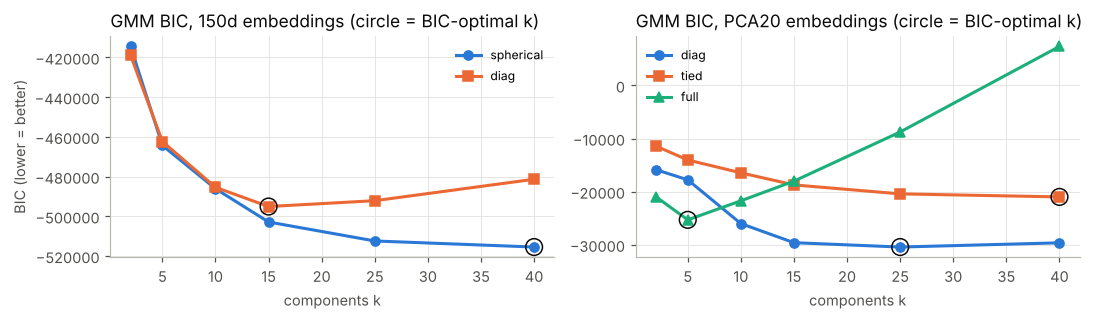

,method,cv_sample_f1,cv_sd,cv_macro_f1,val_sample_f1,val_macro_f1
0,GMM diag k=10,0.694,0.013,0.357,0.726,0.372
1,GMM diag k=25,0.785,0.014,0.530,0.774,0.621
2,GMM diag k=40,0.798,0.002,0.586,0.850,0.590
3,GMM spherical k=10,0.707,0.032,0.383,0.735,0.360
4,GMM spherical k=25,0.783,0.009,0.505,0.799,0.497
5,GMM spherical k=40,0.821,0.016,0.625,0.850,0.593
6,GMM tied k=10,0.623,0.000,0.156,0.624,0.156
7,GMM tied k=25,0.809,0.034,0.608,0.791,0.535
8,GMM tied k=40,0.843,0.009,0.685,0.795,0.513
9,GMM full k=10,0.772,0.010,0.478,0.679,0.285


In [11]:
rows = []
X20 = np.vstack(space('l2', 20)[:2]); X150 = Xtr2
for cov, X, dname in [('spherical', X150, '150d'), ('diag', X150, '150d'), ('diag', X20, 'PCA20'), ('tied', X20, 'PCA20'), ('full', X20, 'PCA20')]:
    for k in [2, 5, 10, 15, 25, 40]:
        g = GaussianMixture(k, covariance_type=cov, random_state=SEED, reg_covar=1e-3, n_init=3, max_iter=500, tol=1e-4).fit(X)
        rows.append(dict(cov=cov, dims=dname, k=k, bic=g.bic(X), converged=g.converged_, n_iter=g.n_iter_))
B2 = pd.DataFrame(rows); B2.to_csv('outputs/expB_gmm_bic.csv', index=False)
display(B2.loc[B2.groupby(['cov', 'dims']).bic.idxmin()])
fig, axs = plt.subplots(1, 2, figsize=(10, 3))  # BIC is only comparable within the same data/dimension
for ax, dims, covs in [(axs[0], '150d', ['spherical', 'diag']), (axs[1], 'PCA20', ['diag', 'tied', 'full'])]:
    for cov, c, mk_ in zip(covs, [BLUE, ORANGE, AQUA], ['o', 's', '^']):
        g = B2[(B2.dims == dims) & (B2['cov'] == cov)]; ax.plot(g.k, g.bic, marker=mk_, color=c, ms=6, label=cov)
        b = g.loc[g.bic.idxmin()]; ax.scatter([b.k], [b.bic], s=120, facecolor='none', edgecolor=INK, zorder=4)
    ax.set_xlabel('components k'); ax.set_title(f'GMM BIC, {dims} embeddings (circle = BIC-optimal k)', loc='left'); ax.legend(fontsize=8)
axs[0].set_ylabel('BIC (lower = better)'); plt.tight_layout(); plt.savefig('figures/fig4_gmm_bic.png'); plt.show()
rows = []
for cov, sp in [('diag', 'l2'), ('spherical', 'l2'), ('tied', space('l2', 20)), ('full', space('l2', 20))]:
    for k in [10, 25, 40]:
        r, m, _ = evaluate(f'GMM {cov} k={k}', lambda k=k, cov=cov: GMMLabel(k, cov), sp, reps=3); r['cov'] = cov; r['k'] = k; rows.append(r)
B3 = pd.DataFrame(rows)[['method', 'cv_sample_f1', 'cv_sd', 'cv_macro_f1', 'val_sample_f1', 'val_macro_f1']]; display(fmt(B3))

**Takeaways (5b)**
- All EM runs converged (≤ 71 iterations). BIC's choice depends strongly on the covariance type: **full** covariances get k = 5 (each component costs ~230 parameters even in 20-d), **diag** in 150-d gets k = 15, and **spherical / tied** hit the top of the grid (k = 40). There is no consistent "true" number of components.
- **BIC-optimal ≠ label-optimal.** BIC rewards density fit, but label transfer depends on whether components align with reasons. Label-transfer F1 keeps improving with k for every covariance type, well past the BIC optimum for diag and full (e.g. diag: k = 15 is BIC-best, but k = 40 transfers labels better). Tied covariances in PCA-20 transfer best (0.843 CV), full covariances worst (~0.78).
- Soft responsibilities (best GMM 0.843) and hard assignments (best K-Means 0.843) tie. Soft posteriors are more useful as **features** for a downstream classifier ("GMM-posterior features" in Exp C, 0.899 CV) than as a direct labeler.

### 5c. Density-based: HDBSCAN / DBSCAN
Points labelled noise (−1), and clusters with no labeled member, fall back to kNN. Cluster members blend the cluster rate with local kNN (0.5/0.5).

In [12]:
rows = []
Xs = np.vstack(SP['std'][:2])
for mcs in [5, 10, 20, 40]:
    h = HDBSCAN(min_cluster_size=mcs).fit(Xs)
    r, _, _ = evaluate(f'HDBSCAN mcs={mcs}', lambda mcs=mcs: DensityLabel('hdbscan', mcs), 'std', reps=3)
    rows.append(dict(algo='HDBSCAN', param=f'min_cluster_size={mcs}', n_clusters=h.labels_.max() + 1, noise_frac=(h.labels_ == -1).mean(), cv_sample_f1=r['cv_sample_f1'], val_sample_f1=r['val_sample_f1']))
for eps in [0.2, 0.3, 0.4, 0.5]:
    d = DBSCAN(eps=eps, min_samples=5, metric='cosine').fit(Xtr2)
    r, _, _ = evaluate(f'DBSCAN eps={eps}', lambda eps=eps: DensityLabel('dbscan', eps=eps), 'l2', reps=3)
    rows.append(dict(algo='DBSCAN', param=f'eps={eps} (cosine)', n_clusters=d.labels_.max() + 1, noise_frac=(d.labels_ == -1).mean(), cv_sample_f1=r['cv_sample_f1'], val_sample_f1=r['val_sample_f1']))
B4 = pd.DataFrame(rows); display(fmt(B4)); B4.to_csv('outputs/expB_density.csv', index=False)

,algo,param,n_clusters,noise_frac,cv_sample_f1,val_sample_f1
0,HDBSCAN,min_cluster_size=5,29,0.548,0.882,0.859
1,HDBSCAN,min_cluster_size=10,13,0.611,0.875,0.859
2,HDBSCAN,min_cluster_size=20,8,0.687,0.875,0.846
3,HDBSCAN,min_cluster_size=40,3,0.790,0.875,0.846
4,DBSCAN,eps=0.2 (cosine),25,0.572,0.875,0.846
5,DBSCAN,eps=0.3 (cosine),15,0.447,0.872,0.833
6,DBSCAN,eps=0.4 (cosine),2,0.274,0.822,0.829
7,DBSCAN,eps=0.5 (cosine),3,0.099,0.796,0.778


**Takeaways (5c)**
- In 150 dimensions **55–79% of trials are noise for HDBSCAN** (more as `min_cluster_size` grows). DBSCAN is very sensitive to `eps`: 0.2–0.3 leaves ~45–57% noise, while 0.4–0.5 collapses everything into 2–3 giant clusters.
- The resulting F1 (0.875–0.882) is about the same as plain kNN (0.877), i.e. dominated by the kNN fallback. Density clustering here mostly *flags outliers*; it doesn't add labeling power.

## 6. Exp C: main comparison of reason-labeling methods
Supervised-only baselines (use only the 157 labels) vs unsupervised and semi-supervised methods (also use the 1,014 unlabeled trials).

- **Self-training:** OvR logistic regression; at each of 5 rounds, add unlabeled trials whose predicted probability is ≥ 0.9 (or ≤ 0.1) for *all five* reasons, then retrain.
- **Augmented LR ← teacher:** a teacher pseudo-labels all 1,014 trials; the student LR trains on 157 true + 1,014 pseudo labels, weighted by teacher confidence |2p − 1| × 0.5.
- **Consensus-augmented LR:** three dissimilar teachers (LR = linear, Label Spreading = graph, kNN = local). Only unlabeled trials where all three agree on the full label set are added (weight 0.5).
- **Balanced consensus:** as above, with positive pseudo-labels re-weighted so each reason's pseudo-label share matches its labeled prior.
- **Ensemble:** average of the probability outputs.

In [13]:
T = lambda: [LR(1), Spread(10), KNN(10)]
methods = [
 ('[sup] LogReg OvR (C=1, balanced)', 'std', lambda: LR(1.0)),
 ('[sup] LogReg OvR (C=1, no class weight)', 'std', lambda: LR(1.0, None)),
 ('[sup] kNN k=10 (cosine)', 'l2', lambda: KNN(10)),
 ('[unsup] K-Means k=50 → label', 'l2', lambda: KMeansLabel(50, n_init=4)),
 ('[unsup] GMM diag k=25 → label', 'l2', lambda: GMMLabel(25, 'diag')),
 ('[unsup] HDBSCAN → label (+kNN)', 'std', lambda: DensityLabel('hdbscan', 5)),
 ('[semi] Label Spreading (kNN graph)', 'l2', lambda: Spread(10)),
 ('[semi] LogReg on emb + GMM posteriors', 'std', lambda: GMMFeatLR(20)),
 ('[semi] Self-training LogReg (thr .9)', 'std', lambda: SelfTrain(1, .9)),
 ('[semi] Augmented LR ← GMM', 'l2', lambda: Augmented(GMMLabel(25), C=10)),
 ('[semi] Augmented LR ← Label Spreading', 'l2', lambda: Augmented(Spread(10), C=10)),
 ('[semi] Consensus-augmented LR', 'std', lambda: Consensus(T(), 1, .5)),
 ('[semi] Balanced consensus LR', 'std', lambda: BalancedConsensus(T(), 1, .5)),
 ('[ens] Self-training + Consensus', 'std', lambda: Ensemble([SelfTrain(1, .9), Consensus(T(), 1, .5)])),
 ('[ens] LR + ST + Consensus + GMM-feat', 'std', lambda: Ensemble([LR(1), SelfTrain(1, .9), Consensus(T(), 1, .5), GMMFeatLR(20)])),
]
rows, MODELS, OOFS = [], {}, {}
for n, sp, mk in methods:
    r, m, oof = evaluate(n, mk, sp, reps=5); rows.append(r); MODELS[n] = m; OOFS[n] = oof
    print(f"{n:42s} CV {r['cv_sample_f1']:.3f}±{r['cv_sd']:.3f}  val {r['val_sample_f1']:.3f}  ({r['sec']:.0f}s)")
MAIN = pd.DataFrame(rows); MAIN.to_csv('outputs/expC_main_comparison.csv', index=False)
display(fmt(MAIN.drop(columns=['sec'])))

[sup] LogReg OvR (C=1, balanced)           CV 0.895±0.008  val 0.870  (0s)


[sup] LogReg OvR (C=1, no class weight)    CV 0.893±0.006  val 0.850  (0s)
[sup] kNN k=10 (cosine)                    CV 0.877±0.008  val 0.846  (0s)


[unsup] K-Means k=50 → label               CV 0.835±0.014  val 0.799  (2s)


[unsup] GMM diag k=25 → label              CV 0.787±0.011  val 0.774  (8s)


[unsup] HDBSCAN → label (+kNN)             CV 0.886±0.008  val 0.859  (4s)


[semi] Label Spreading (kNN graph)         CV 0.850±0.007  val 0.859  (1s)


... (5 outputs left out)

[semi] Balanced consensus LR               CV 0.903±0.007  val 0.882  (4s)


[ens] Self-training + Consensus            CV 0.898±0.011  val 0.900  (8s)


[ens] LR + ST + Consensus + GMM-feat       CV 0.901±0.009  val 0.891  (16s)


,method,space,cv_sample_f1,cv_sd,cv_macro_f1,val_sample_f1,val_macro_f1,val_F1_Safety,val_F1_Funding,val_F1_Efficacy,val_F1_Recruitment,val_F1_Other
0,"[sup] LogReg OvR (C=1, balanced)",std,0.895,0.008,0.827,0.870,0.762,0.889,0.667,0.720,0.961,0.571
1,"[sup] LogReg OvR (C=1, no class weight)",std,0.893,0.006,0.817,0.850,0.680,0.941,0.400,0.667,0.971,0.421
2,[sup] kNN k=10 (cosine),l2,0.877,0.008,0.758,0.846,0.594,0.750,0.000,0.769,0.951,0.500
3,[unsup] K-Means k=50 → label,l2,0.835,0.014,0.668,0.799,0.535,0.667,0.000,0.526,0.942,0.538
4,[unsup] GMM diag k=25 → label,l2,0.787,0.011,0.523,0.774,0.621,0.429,0.750,0.435,0.920,0.571
5,[unsup] HDBSCAN → label (+kNN),std,0.886,0.008,0.768,0.859,0.595,0.667,0.000,0.846,0.962,0.500
6,[semi] Label Spreading (kNN graph),l2,0.850,0.007,0.693,0.859,0.601,0.824,0.000,0.667,0.990,0.526
7,[semi] LogReg on emb + GMM posteriors,std,0.899,0.006,0.827,0.868,0.715,0.941,0.400,0.720,0.970,0.545
8,[semi] Self-training LogReg (thr .9),std,0.898,0.010,0.817,0.897,0.789,0.941,0.667,0.828,0.990,0.522
9,[semi] Augmented LR ← GMM,l2,0.862,0.009,0.751,0.859,0.775,0.842,0.889,0.621,0.980,0.545


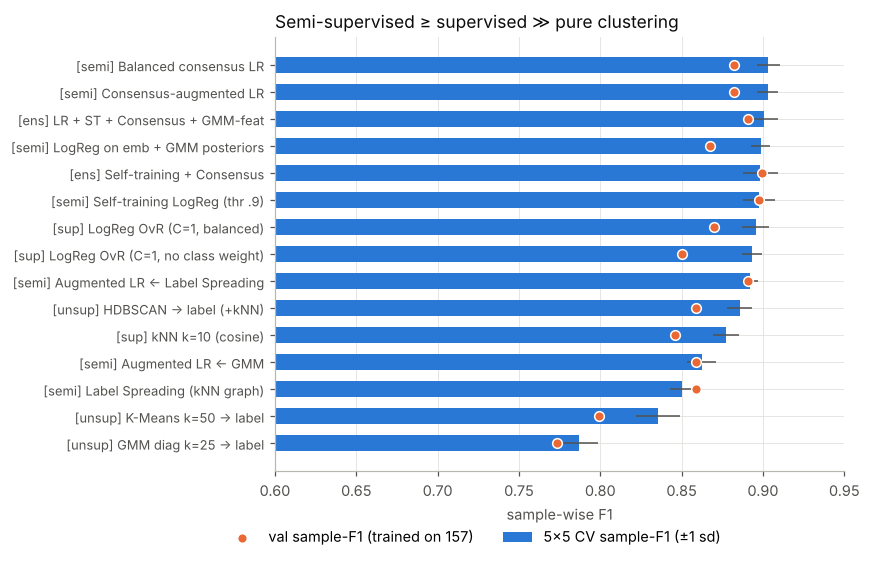

Consensus: teachers agree on 72.7% of unlabeled trials; pseudo-label rates among agreed: {'Safety': np.float64(0.069), 'Funding': np.float64(0.003), 'Efficacy': np.float64(0.08), 'Recruitment': np.float64(0.825), 'Other': np.float64(0.024)}
Self-training: pseudo-labeled trials added in last round: 806


In [14]:
d = MAIN.sort_values('cv_sample_f1'); y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(y, d.cv_sample_f1, xerr=d.cv_sd, color=BLUE, height=.6, label='5×5 CV sample-F1 (±1 sd)', error_kw=dict(ecolor=INK2, lw=1))
ax.scatter(d.val_sample_f1, y, color=ORANGE, s=40, zorder=3, edgecolor='white', linewidth=1, label='val sample-F1 (trained on 157)')
ax.set_yticks(y, d.method, fontsize=8.5); ax.set_xlim(.6, .95); ax.set_xlabel('sample-wise F1')
ax.legend(loc='upper center', bbox_to_anchor=(.35, -.1), ncol=2)
ax.set_title('Semi-supervised ≥ supervised ≫ pure clustering', loc='left')
plt.tight_layout(); plt.savefig('figures/fig5_method_comparison.png'); plt.show()
cons = MODELS['[semi] Consensus-augmented LR']; st = MODELS['[semi] Self-training LogReg (thr .9)']
print(f"Consensus: teachers agree on {cons.agree_frac:.1%} of unlabeled trials; pseudo-label rates among agreed:",
      dict(zip(L, cons.Yu[cons.agree].mean(0).round(3))))
print('Self-training: pseudo-labeled trials added in last round:', st.n_pseudo)

**Takeaways (Exp C)**
- **Pure clustering → label is clearly worst** (K-Means / GMM ≈ 0.79–0.84 sample-F1). The clusters don't align with reasons finely enough, and rare reasons get absorbed by Recruitment-heavy clusters (Funding F1 often 0).
- **A plain OvR logistic regression on 157 labels is a strong baseline (~0.895 CV)**. The reason embeddings are already a supervised-quality representation (they come from a pretrained sentence encoder applied to the stop-reason text).
- **Semi-supervised methods that keep a discriminative student on top win**: consensus-augmented LR (best CV) and self-training (best val). The gains are about +0.5–1 point CV and +1–3 points val, roughly 1 sd of the CV noise. That's real but modest, which is what we expect when the labeled set already covers the space reasonably well (see the learning curve in Exp D).
- **Consensus filtering trades coverage for precision:** the three teachers agree on ~73% of unlabeled trials, but the agreed set is *biased toward easy Recruitment cases* (Funding/Other are almost never agreed). Re-weighting rare positives (balanced consensus) changed nothing, because there are almost no rare positive pseudo-labels to re-weight.
- **Label Spreading alone underperforms LR**, but it is a valuable *teacher*: it makes errors different from LR's, which is exactly what consensus needs.
- **Class weighting matters for macro-F1:** `class_weight='balanced'` keeps Funding/Other recall alive with only 8 / 25 positives.

## 7. Exp D: learning curve — when does the unlabeled data help?
Subsample n of the 157 labeled trials (10 random draws each). The remaining labeled trials join the unlabeled pool, with labels hidden. Score on val.

method,Consensus-augmented LR,Label Spreading,LogReg (supervised),Self-training
n,,,,
15,0.702,0.712,0.732,0.739
30,0.760,0.762,0.766,0.771
60,0.839,0.813,0.853,0.871
100,0.849,0.831,0.851,0.854
157,0.882,0.859,0.870,0.897


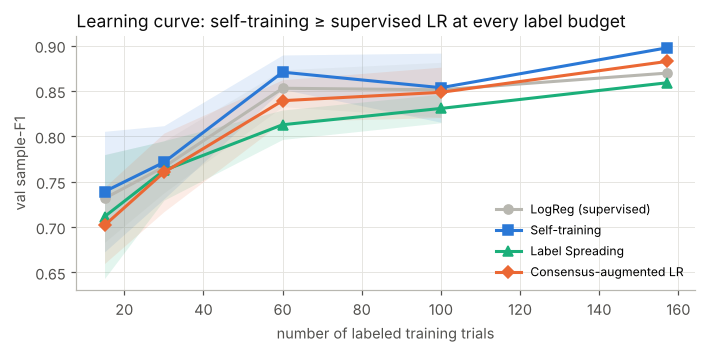

In [15]:
Xl, Xu, Xv, Xt = SP['std']; rng = np.random.default_rng(SEED); rows = []
LC = {'LogReg (supervised)': lambda: LR(1), 'Self-training': lambda: SelfTrain(1, .9),
      'Label Spreading': lambda: Spread(10), 'Consensus-augmented LR': lambda: Consensus(T(), 1, .5)}
for n in [15, 30, 60, 100, 157]:
    for s in range(10 if n < 157 else 1):
        i = rng.choice(len(Xl), n, replace=False) if n < 157 else np.arange(len(Xl))
        Xua = np.vstack([Xu, np.delete(Xl, i, 0)])
        for k, mk in LC.items():
            sp = SP['l2'] if k == 'Label Spreading' else SP['std']
            Xa, Xva, Xuu = sp[0][i], sp[2], np.vstack([sp[1], np.delete(sp[0], i, 0)])
            rows.append(dict(n=n, seed=s, method=k, val_sample_f1=metrics(Yv, decide(mk().fit(Xa, Yl[i], Xuu).predict_proba(Xva), .5))['sample_f1']))
LCD = pd.DataFrame(rows); LCD.to_csv('outputs/expD_learning_curve.csv', index=False)
g = LCD.groupby(['method', 'n']).val_sample_f1.agg(['mean', 'std']).reset_index(); display(g.pivot(index='n', columns='method', values='mean').round(3))
fig, ax = plt.subplots(figsize=(6.5, 3.3))
for (k, c, mk_) in zip(LC, [GRAY, BLUE, AQUA, ORANGE], ['o', 's', '^', 'D']):
    gg = g[g.method == k]; ax.plot(gg.n, gg['mean'], marker=mk_, color=c, ms=6, label=k)
    ax.fill_between(gg.n, gg['mean'] - gg['std'], gg['mean'] + gg['std'], color=c, alpha=.12, lw=0)
ax.set_xlabel('number of labeled training trials'); ax.set_ylabel('val sample-F1'); ax.legend(fontsize=8)
ax.set_title('Learning curve: self-training ≥ supervised LR at every label budget', loc='left')
plt.tight_layout(); plt.savefig('figures/fig6_learning_curve.png'); plt.show()

**Takeaways (Exp D)**
- **Self-training is ≥ supervised LR at every label budget.** Its pseudo-labels come from the same model family, so they add confident, low-noise examples that shift the decision boundary toward low-density regions.
- **Consensus only beats LR at the full 157 labels** (0.882 vs 0.870). With fewer labels, kNN and Label Spreading are weak teachers. Agreement between weak teachers mostly certifies easy Recruitment cases, which adds little.
- **Graph-based Label Spreading alone is always below LR.** The kNN graph in 150-d connects trials with different reasons (hubness), and spreading propagates those mistakes.

## 8. Exp E: feature ablation — why including everything does not help
Each non-embedding block is appended to the standardized embeddings (at weight 1 and down-weighted ×0.3), with OvR LR (C = 1). Blocks: `start_year`; disease TF-IDF (1–2-grams → SVD-30); eligibility-criteria TF-IDF (1–2-grams, sublinear, stop words → SVD-50); ICD-10 chapter multi-hot; Morgan fingerprints (r = 2, 1024 bits, element-wise max over a trial's drugs, zeros if unmatched → SVD-30); Reactome pathway multi-hot (levels 0–1); drug actions multi-hot (≥ 5 occurrences); matched-drug indicator.

In [16]:
B = build_blocks(tr, va, te, catalog, SEED)
Etr, Ev, Et = prep_emb(tr[EMB].values, [tr[EMB].values, va[EMB].values, te[EMB].values], 'std')
def fspace(names, wt=1.0, emb=True):
    parts = ([(Etr, Ev, Et)] if emb else []) + [tuple(wt * x for x in B[n]) for n in names]
    Ftr, Fv, Ft = [np.hstack([p[i] for p in parts]) for i in range(3)]
    return Ftr[islab], Ftr[~islab], Fv, Ft
rows = []
for names in [[]] + [[n] for n in B] + [list(B)]:
    for wt in ([1.0] if not names else [1.0, 0.3]):
        r, _, _ = evaluate('+'.join(names) or 'embeddings only', lambda: LR(1.0), fspace(names, wt), reps=5)
        rows.append(dict(features='emb + ' + ('+'.join(names) if names else '—'), block_weight=wt, dims=fspace(names)[0].shape[1], **{k: r[k] for k in ['cv_sample_f1', 'cv_sd', 'cv_macro_f1', 'val_sample_f1', 'val_macro_f1']}))
r, _, _ = evaluate('no embeddings', lambda: LR(1.0), fspace(list(B), 1.0, emb=False), reps=5)
rows.append(dict(features='ALL non-embedding blocks, NO embeddings', block_weight=1.0, dims=fspace(list(B), emb=False)[0].shape[1], **{k: r[k] for k in ['cv_sample_f1', 'cv_sd', 'cv_macro_f1', 'val_sample_f1', 'val_macro_f1']}))
E = pd.DataFrame(rows); E.to_csv('outputs/expE_feature_ablation.csv', index=False); display(fmt(E))

,features,block_weight,dims,cv_sample_f1,cv_sd,cv_macro_f1,val_sample_f1,val_macro_f1
0,emb + —,1.000,150,0.895,0.008,0.827,0.870,0.762
1,emb + start_year,1.000,151,0.893,0.009,0.822,0.870,0.766
2,emb + start_year,0.300,151,0.895,0.008,0.825,0.870,0.762
3,emb + disease_tfidf,1.000,180,0.890,0.008,0.808,0.863,0.696
4,emb + disease_tfidf,0.300,180,0.894,0.007,0.820,0.870,0.762
5,emb + criteria_tfidf,1.000,200,0.898,0.008,0.816,0.872,0.770
6,emb + criteria_tfidf,0.300,200,0.897,0.007,0.827,0.865,0.708
7,emb + icd_chapter,1.000,172,0.896,0.007,0.825,0.870,0.762
8,emb + icd_chapter,0.300,172,0.895,0.008,0.826,0.870,0.762
9,emb + morgan_fp_svd,1.000,180,0.899,0.007,0.820,0.863,0.741


**Takeaways (Exp E)**
- **No feature block improves on embeddings-only beyond CV noise (±0.008).** Adding *all* blocks (~350 extra dims) gives the same CV but **lower val sample-F1 and macro-F1**.
- **Without the embeddings, the other features alone score far lower.** The stopping reason is a property of what happened *to the trial*, recorded in the `why_stop` text (and hence the embeddings). The drugs, diseases and eligibility criteria describe the trial *design*, which only weakly predicts why it stopped (e.g. oncology trials stop for Efficacy somewhat more often).
- **Why "everything" fails:** (1) with 157 labels, every extra noisy dimension costs variance (curse of dimensionality / overfitting with roughly 2 samples per feature); (2) drug features are missing for 44% of trials (all-zero fingerprints), so they mostly encode "was a small molecule matched", a dataset artefact; (3) TF-IDF criteria are long boilerplate whose top SVD directions encode the therapeutic area, not the stop reason; (4) `start_year` is the one block with a plausible link (the prior shift), but within the labeled range it adds nothing, and extrapolating a linear year trend to 2010–2016 is risky. We handle the shift more safely with the EM prior correction (Exp G).
- **Final feature choice: the 150 standardized reason embeddings only.**

## 9. Exp F: decision thresholds

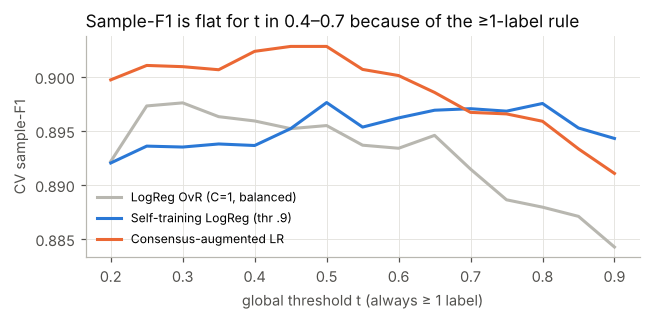

per-label CV-optimal thresholds: {'Safety': np.float64(0.6), 'Funding': np.float64(0.35), 'Efficacy': np.float64(0.5), 'Recruitment': np.float64(0.5), 'Other': np.float64(0.6)}
global t=0.5           CV sample-F1 0.903  macro-F1 0.824
per-label thresholds   CV sample-F1 0.903  macro-F1 0.822


In [17]:
grid = np.round(np.arange(.2, .91, .05), 2); Yp = np.vstack([Yl, Yv])
fig, ax = plt.subplots(figsize=(6, 3))
for k, c in [('[sup] LogReg OvR (C=1, balanced)', GRAY), ('[semi] Self-training LogReg (thr .9)', BLUE), ('[semi] Consensus-augmented LR', ORANGE)]:
    ax.plot(grid, [np.mean([metrics(Yp, decide(P, t))['sample_f1'] for P in OOFS[k]]) for t in grid], color=c, label=k.split('] ')[1])
ax.set_xlabel('global threshold t (always ≥ 1 label)'); ax.set_ylabel('CV sample-F1'); ax.legend(fontsize=8)
ax.set_title('Sample-F1 is flat for t in 0.4–0.7 because of the ≥1-label rule', loc='left')
plt.tight_layout(); plt.savefig('figures/fig7_threshold.png'); plt.show()
k = '[semi] Consensus-augmented LR'; O = OOFS[k]
ts = [grid[np.argmax([np.mean([f1_score(Yp[:, j], (P[:, j] >= t).astype(int)) for P in O]) for t in grid])] for j in range(5)]
print('per-label CV-optimal thresholds:', dict(zip(L, ts)))
for nm, fn in [('global t=0.5', lambda P: decide(P, .5)), ('per-label thresholds', lambda P: decide_pl(P, ts))]:
    print(f"{nm:22s} CV sample-F1 {np.mean([metrics(Yp, fn(P))['sample_f1'] for P in O]):.3f}  macro-F1 {np.mean([metrics(Yp, fn(P))['macro_f1'] for P in O]):.3f}")

**Takeaways (Exp F)** The "≥ 1 label via arg-max" rule does most of the work: ~93% of trials have one reason, so the arg-max already decides most predictions and the threshold only controls the occasional second label. Per-label thresholds tuned by CV give no gain and would overfit on 8 Funding positives. **We keep a single global t = 0.5.**

## 10. Exp G: label-prior shift (early → late trials)
The labeled trials are the earliest ones, plus 40 trials chosen to over-represent rare reasons, so their label prior does not match later trials. Under a *prior-shift* assumption (p(x | y) fixed, p(y) changes), the EM procedure of **Saerens, Latinne & Decaestecker (2002)** re-estimates the target-set prior from the model's own unlabeled predictions and re-calibrates the posteriors. We run it per reason (binary EM). We can check it on val, where the true prior is known.

,Safety,Funding,Efficacy,Recruitment,Other
labeled train (prior used in training),0.102,0.051,0.108,0.643,0.159
val TRUE,0.115,0.051,0.179,0.641,0.128
val EM-estimate,0.113,0.020,0.214,0.645,0.123
unlabeled-train EM-estimate,0.099,0.014,0.148,0.697,0.130
test EM-estimate,0.183,0.020,0.171,0.566,0.211


val no adjustment        sample-F1 0.900 macro-F1 0.787
val EM prior adjustment  sample-F1 0.900 macro-F1 0.777


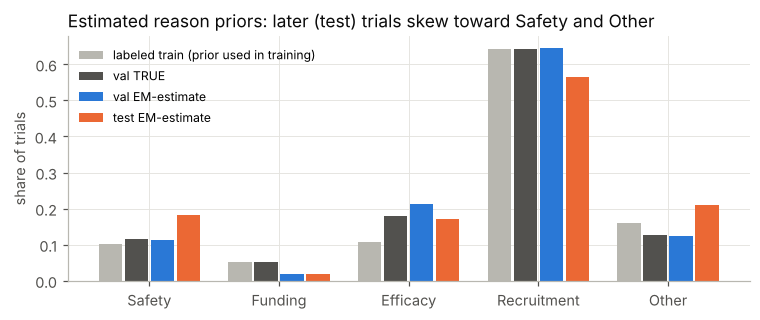

In [18]:
m = MODELS['[ens] Self-training + Consensus']; prior = Yl.mean(0)
Pv = m.predict_proba(SP['std'][2]); Pt = m.predict_proba(SP['std'][3]); Pu = m.predict_proba(SP['std'][1])
Pv_adj, pi_v = em_prior_shift(Pv, prior); Pt_adj, pi_t = em_prior_shift(Pt, prior); _, pi_u = em_prior_shift(Pu, prior)
G = pd.DataFrame({'labeled train (prior used in training)': prior, 'val TRUE': Yv.mean(0), 'val EM-estimate': pi_v,
                  'unlabeled-train EM-estimate': pi_u, 'test EM-estimate': pi_t}, index=L).T.round(3); display(G)
for nm, P in [('no adjustment', Pv), ('EM prior adjustment', Pv_adj)]:  # val check
    v = metrics(Yv, decide(P, .5)); print(f"val {nm:20s} sample-F1 {v['sample_f1']:.3f} macro-F1 {v['macro_f1']:.3f}")
G.to_csv('outputs/expG_prior_shift.csv')
fig, ax = plt.subplots(figsize=(7, 3)); w = .2; x = np.arange(5)
for i, (row, c) in enumerate(zip(['labeled train (prior used in training)', 'val TRUE', 'val EM-estimate', 'test EM-estimate'], [GRAY, INK2, BLUE, ORANGE])):
    ax.bar(x + (i - 1.5) * w, G.loc[row], w * .9, color=c, label=row)
ax.set_xticks(x, L); ax.set_ylabel('share of trials'); ax.legend(fontsize=8)
ax.set_title('Estimated reason priors: later (test) trials skew toward Safety and Other', loc='left')
plt.tight_layout(); plt.savefig('figures/fig8_prior_shift.png'); plt.show()

**Takeaways (Exp G)**
- On val, EM moves the Efficacy prior in the right direction (0.108 → 0.214; true 0.179) but overshoots, and it under-estimates Funding. For our final ensemble, **val sample-F1 is unchanged and macro-F1 drops slightly**. For single models it was mixed (it helped consensus LR, hurt plain LR). So EM is **not validated as an improvement**.
- On test (2010–2016), EM estimates a **higher Safety and Other share and a lower Recruitment share** than in the labeled set. This matches the trend the spec describes, recovered without seeing any test label.
- Key insight: **the classifier already tracks most of this shift.** Its raw test predictions contain ~16% Safety vs a 10% training prior, because the shift is visible in the embeddings themselves (later trials really do have Safety-like reason texts). Applying EM changes only ~14 of 312 test predictions. Since it isn't validated to help, **the primary submission uses no EM**; the EM version is saved as an alternate.
- Optional transductive check: also feeding val+test embeddings as unlabeled points changes val F1 by less than CV noise. We do **not** use it for the submission, to keep test features out of training.

In [19]:
r_tr, _, _ = evaluate('Consensus (transductive U)', lambda: Consensus(T(), 1, .5), (SP['std'][0], np.vstack([SP['std'][1], SP['std'][2], SP['std'][3]]), SP['std'][2], SP['std'][3]), reps=1)
print('transductive val sample-F1:', round(r_tr['val_sample_f1'], 3), '| inductive:', round(MAIN.set_index('method').loc['[semi] Consensus-augmented LR', 'val_sample_f1'], 3))

transductive val sample-F1: 0.887 | inductive: 0.882


## 11. Final model, Kaggle submission, and Part 2 handoff
**Chosen model:** ensemble (probability average) of **self-training LR** and **consensus-augmented LR**, on standardized reason embeddings, global t = 0.5 with the ≥ 1-label rule, no prior correction (Exp G). It has the best val score and is within noise of the best CV, and averaging two different SSL schemes lowers variance. The EM-corrected version is written as an alternate file (`part1_submission_alt_em.csv`).

1. **Validation numbers** come from the model trained on the 157 labeled trials (+ 1,014 unlabeled), with a bootstrap 95% CI.
2. **For the submission and the pseudo-labels** we refit on all 235 labeled trials (157 + val 78). Model selection is finished, and val is the closest-in-time labeled data we have.

In [20]:
FINAL = lambda: Ensemble([SelfTrain(1, .9), Consensus(T(), 1, .5)])
Xl, Xu, Xv, Xt = SP['std']
mv = FINAL().fit(Xl, Yl, Xu); Pv = mv.predict_proba(Xv)
Yhat_v = decide(Pv, .5); vm = metrics(Yv, Yhat_v); print('VAL (trained on 157 labeled):', {k: round(v, 3) for k, v in vm.items()})
rng = np.random.default_rng(SEED); bs = []
for _ in range(2000):
    i = rng.integers(0, len(Yv), len(Yv)); bs.append(f1_score(Yv[i], Yhat_v[i], average='samples', zero_division=0))
print('val sample-F1 95% bootstrap CI:', np.percentile(bs, [2.5, 97.5]).round(3))
# per-reason confusion on val
display(pd.DataFrame({'support': Yv.sum(0), 'predicted': Yhat_v.sum(0), 'TP': (Yv & Yhat_v).sum(0)}, index=L).T)

VAL (trained on 157 labeled): {'sample_f1': 0.9, 'macro_f1': np.float64(0.787), 'F1_Safety': np.float64(0.889), 'F1_Funding': np.float64(0.667), 'F1_Efficacy': np.float64(0.828), 'F1_Recruitment': np.float64(0.98), 'F1_Other': np.float64(0.571)}


val sample-F1 95% bootstrap CI: [0.844 0.949]


,Safety,Funding,Efficacy,Recruitment,Other
support,9,4,14,50,10
predicted,9,2,15,50,11
TP,8,2,12,49,6


In [21]:
# refit on all labeled data (train-labeled + val) for test + pseudo-labels
Xall_l = np.vstack([Xl, Xv]); Yall_l = np.vstack([Yl, Yv]); prior_all = Yall_l.mean(0)
mf = FINAL().fit(Xall_l, Yall_l, Xu)
Pt, Pu = mf.predict_proba(Xt), mf.predict_proba(Xu); Yt, Yu = decide(Pt, .5), decide(Pu, .5)
Pt_em, pi_t = em_prior_shift(Pt, prior_all); Yt_em = decide(Pt_em, .5)
print('test predicted label rates:', dict(zip(L, Yt.mean(0).round(3))), '| labels per trial:', np.bincount(Yt.sum(1)))
print('EM test prior:', dict(zip(L, pi_t.round(3))), '| test rows changed by EM:', int((Yt != Yt_em).any(1).sum()))
sample = pd.read_csv(D + 'part1_sample_submission.csv')
def write_sub(Y, path):
    sub = pd.DataFrame({'ID': te.ID, 'Predicted': [' '.join(l for l, y in zip(L, row) if y) for row in Y]})
    assert set(sub.ID) == set(sample.ID) and len(sub) == len(sample) and (sub.Predicted.str.len() > 0).all()
    sub = sub.set_index('ID').loc[sample.ID].reset_index(); sub.to_csv(path, index=False); return sub
sub = write_sub(Yt, 'outputs/part1_submission.csv'); write_sub(Yt_em, 'outputs/part1_submission_alt_em.csv'); display(sub.head())

test predicted label rates: {'Safety': np.float64(0.157), 'Funding': np.float64(0.029), 'Efficacy': np.float64(0.16), 'Recruitment': np.float64(0.587), 'Other': np.float64(0.26)} | labels per trial: [  0 254  56   2]
EM test prior: {'Safety': np.float64(0.168), 'Funding': np.float64(0.026), 'Efficacy': np.float64(0.17), 'Recruitment': np.float64(0.555), 'Other': np.float64(0.293)} | test rows changed by EM: 14


,ID,Predicted
0,TR00756,Efficacy
1,TR05267,Safety Other
2,TR10354,Safety
3,TR01930,Recruitment
4,TR01046,Efficacy


In [22]:
# Handoff file for Part 2: every Part 1 trial, true labels where available, predictions otherwise
def block(df, Y, P, src):
    out = pd.DataFrame({'ID': df.ID.values, 'start_year': df.start_year.values, 'label_source': src})
    for j, l in enumerate(L):
        out[l] = Y[:, j].astype(int); out[f'p_{l}'] = np.round(P[:, j], 4) if P is not None else np.nan
    return out
H = pd.concat([block(lab, Yl, None, 'true_train'), block(va, Yv, None, 'true_val'),
               block(unl, Yu, Pu, 'predicted_train_unlabeled'), block(te, Yt, Pt, 'predicted_test')], ignore_index=True)
assert H.ID.is_unique and len(H) == 1561 and (H[L].sum(axis=1) >= 1).all()
H.to_csv('outputs/part1_reason_labels_all_trials.csv', index=False)
display(H.label_source.value_counts()); display(H.groupby('label_source')[L].mean().round(3))

label_source
predicted_train_unlabeled    1014
predicted_test                312
true_train                    157
true_val                       78
Name: count, dtype: int64

,Safety,Funding,Efficacy,Recruitment,Other
label_source,,,,,
predicted_test,0.157,0.029,0.160,0.587,0.260
predicted_train_unlabeled,0.096,0.020,0.152,0.688,0.185
true_train,0.102,0.051,0.108,0.643,0.159
true_val,0.115,0.051,0.179,0.641,0.128


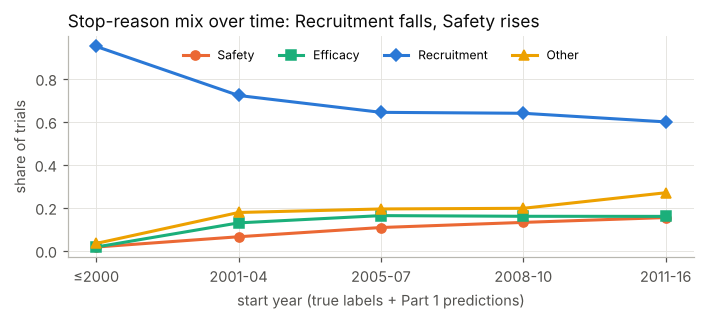

,Safety,Funding,Efficacy,Recruitment,Other
period,,,,,
≤2000,0.017,0.000,0.017,0.950,0.033
2001-04,0.065,0.020,0.129,0.722,0.177
2005-07,0.107,0.024,0.163,0.643,0.194
2008-10,0.131,0.031,0.160,0.639,0.197
2011-16,0.154,0.038,0.159,0.599,0.269


In [23]:
# Insight: reason mix over time (true labels where known, final predictions elsewhere)
yr = H.assign(period=pd.cut(H.start_year, [1990, 2000, 2004, 2007, 2010, 2017], labels=['≤2000', '2001-04', '2005-07', '2008-10', '2011-16'], right=True))
mix = yr.groupby('period', observed=True)[L].mean()
fig, ax = plt.subplots(figsize=(6.5, 3))
for l, c, mk_ in zip(['Safety', 'Efficacy', 'Recruitment', 'Other'], [ORANGE, AQUA, BLUE, YELLOW], ['o', 's', 'D', '^']):
    ax.plot(mix.index.astype(str), mix[l], marker=mk_, color=c, ms=6, label=l)
ax.set_ylabel('share of trials'); ax.set_xlabel('start year (true labels + Part 1 predictions)'); ax.legend(fontsize=8, ncol=4, loc='upper center')
ax.set_title('Stop-reason mix over time: Recruitment falls, Safety rises', loc='left')
plt.tight_layout(); plt.savefig('figures/fig9_reason_mix_over_time.png'); plt.show(); display(mix.round(3))

Caveat: the ≤ 2000 bin is almost entirely *true* labels from the earliest-10% labeled trials, and the 2011–16 bin is entirely *predictions*. The trend is consistent with the spec's description (Safety more common later, Recruitment more common early), but the late bins inherit any bias in our model.

## 12. Results summary

In [24]:
summary = MAIN[['method', 'space', 'cv_sample_f1', 'cv_sd', 'cv_macro_f1', 'val_sample_f1', 'val_macro_f1'] + [f'val_F1_{l}' for l in L]].copy()
final_row = dict(method='FINAL: Ens(Self-training + Consensus), t=0.5', space='std', cv_sample_f1=np.nan, cv_sd=np.nan, cv_macro_f1=np.nan,
                 val_sample_f1=vm['sample_f1'], val_macro_f1=vm['macro_f1'], **{f'val_F1_{l}': vm[f'F1_{l}'] for l in L})
summary = pd.concat([summary, pd.DataFrame([final_row])], ignore_index=True); summary.to_csv('outputs/part1_results_summary.csv', index=False)
display(fmt(summary))

,method,space,cv_sample_f1,cv_sd,cv_macro_f1,val_sample_f1,val_macro_f1,val_F1_Safety,val_F1_Funding,val_F1_Efficacy,val_F1_Recruitment,val_F1_Other
0,"[sup] LogReg OvR (C=1, balanced)",std,0.895,0.008,0.827,0.870,0.762,0.889,0.667,0.720,0.961,0.571
1,"[sup] LogReg OvR (C=1, no class weight)",std,0.893,0.006,0.817,0.850,0.680,0.941,0.400,0.667,0.971,0.421
2,[sup] kNN k=10 (cosine),l2,0.877,0.008,0.758,0.846,0.594,0.750,0.000,0.769,0.951,0.500
3,[unsup] K-Means k=50 → label,l2,0.835,0.014,0.668,0.799,0.535,0.667,0.000,0.526,0.942,0.538
4,[unsup] GMM diag k=25 → label,l2,0.787,0.011,0.523,0.774,0.621,0.429,0.750,0.435,0.920,0.571
5,[unsup] HDBSCAN → label (+kNN),std,0.886,0.008,0.768,0.859,0.595,0.667,0.000,0.846,0.962,0.500
6,[semi] Label Spreading (kNN graph),l2,0.850,0.007,0.693,0.859,0.601,0.824,0.000,0.667,0.990,0.526
7,[semi] LogReg on emb + GMM posteriors,std,0.899,0.006,0.827,0.868,0.715,0.941,0.400,0.720,0.970,0.545
8,[semi] Self-training LogReg (thr .9),std,0.898,0.010,0.817,0.897,0.789,0.941,0.667,0.828,0.990,0.522
9,[semi] Augmented LR ← GMM,l2,0.862,0.009,0.751,0.859,0.775,0.842,0.889,0.621,0.980,0.545


**References**
- Saerens, Latinne & Decaestecker (2002). *Adjusting the outputs of a classifier to new a priori probabilities: a simple procedure.* Neural Computation 14(1).
- Zhou et al. (2004). *Learning with local and global consistency* (Label Spreading). NIPS.
- Yarowsky (1995) / Scudder (1965), self-training; Blum & Mitchell (1998), co-training (motivates multi-teacher agreement).
- Campello, Moulavi & Sander (2013). HDBSCAN. Ester et al. (1996). DBSCAN.
- Fu et al. (2022). *HINT: Hierarchical interaction network for clinical-trial outcome prediction.* Patterns.
- scikit-learn (Pedregosa et al., 2011); RDKit (Morgan fingerprints, Rogers & Hahn 2010).